Assessed 500/5799 images
Assessed 1000/5799 images
Assessed 1500/5799 images
Assessed 2000/5799 images
Assessed 2500/5799 images
Assessed 3000/5799 images
Assessed 3500/5799 images
Assessed 4000/5799 images
Assessed 4500/5799 images
Assessed 5000/5799 images
Assessed 5500/5799 images
Assessed 5799/5799 images


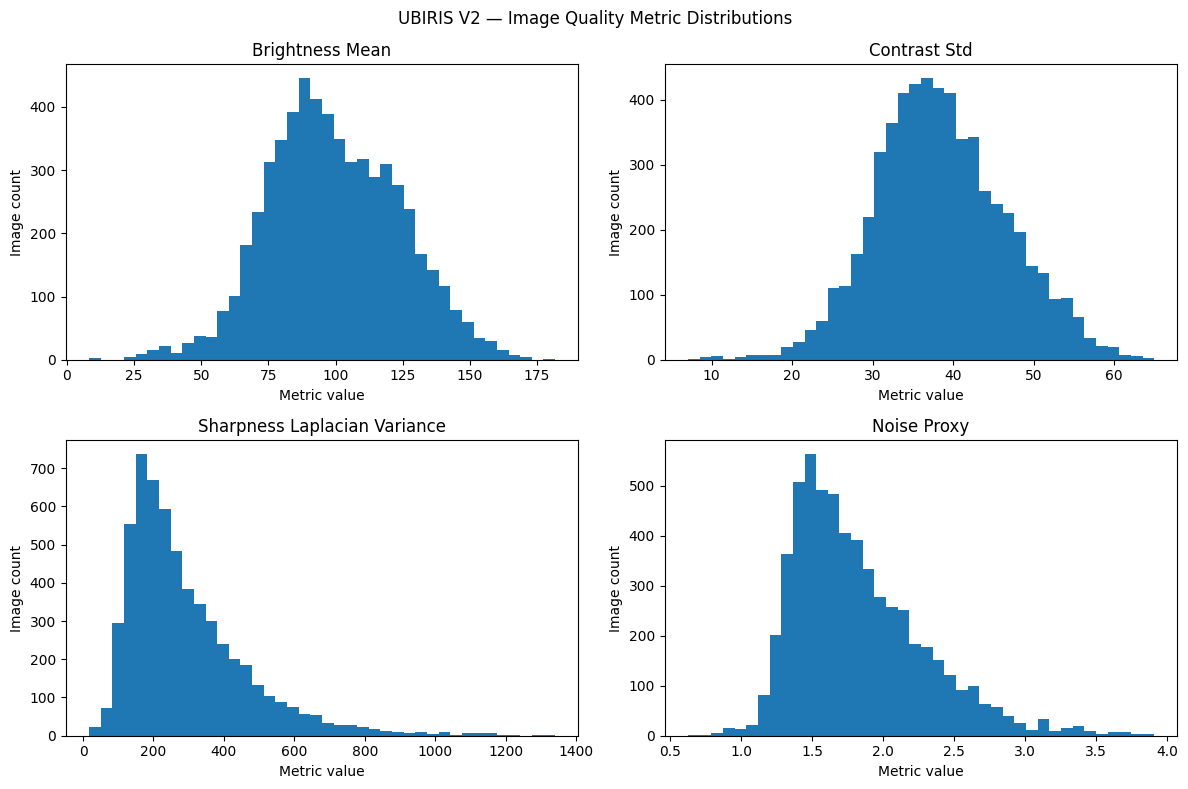


QUALITY ASSESSMENT SUMMARY
{
  "dataset": "UBIRIS V2",
  "images_found": 5799,
  "images_assessed": 5799,
  "failed_images": 0,
  "image_dimensions": "224x224 grayscale",
  "metrics": {
    "brightness_mean": {
      "mean": 99.37974432579998,
      "std": 24.27898171530451,
      "min": 8.20589542388916,
      "median": 97.5596923828125,
      "max": 181.74496459960938
    },
    "contrast_std": {
      "mean": 38.494993567610635,
      "std": 8.101103125783863,
      "min": 7.047779560089111,
      "median": 37.99264907836914,
      "max": 64.96760559082031
    },
    "sharpness_laplacian_variance": {
      "mean": 293.14099960767885,
      "std": 173.05352165335754,
      "min": 16.8518009185791,
      "median": 246.47344970703125,
      "max": 1340.61962890625
    },
    "noise_proxy": {
      "mean": 1.822077829789696,
      "std": 0.4620099540334524,
      "min": 0.6242585778236389,
      "median": 1.721691370010376,
      "max": 3.907620906829834
    }
  },
  "limitations": [
 

In [3]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import json, time
import matplotlib.pyplot as plt

# ---------- Paths ----------
PROJECT = Path("/kaggle/working/ubiris_v2_project")
PRE_DIR = PROJECT / "notebook02_preprocessing"
IMG_DIR = PRE_DIR / "images_224"
OUT_DIR = PROJECT / "notebook03_quality_assessment"
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert IMG_DIR.exists(), f"Missing preprocessed images: {IMG_DIR}"
files = sorted(IMG_DIR.glob("*.png"))
assert files, "No preprocessed PNG images found."

start = time.time()
rows, errors = [], []

def image_metrics(arr):
    arr = arr.astype(np.float32)
    brightness = float(arr.mean())
    contrast = float(arr.std())

    # Laplacian variance as a simple sharpness proxy
    lap = (
        -4 * arr
        + np.roll(arr, 1, axis=0)
        + np.roll(arr, -1, axis=0)
        + np.roll(arr, 1, axis=1)
        + np.roll(arr, -1, axis=1)
    )
    sharpness = float(lap.var())

    # Exploratory high-frequency residual proxy, not calibrated sensor noise
    smooth = (
        arr
        + np.roll(arr, 1, axis=0)
        + np.roll(arr, -1, axis=0)
        + np.roll(arr, 1, axis=1)
        + np.roll(arr, -1, axis=1)
    ) / 5.0
    noise_proxy = float(np.mean(np.abs(arr - smooth)))

    return brightness, contrast, sharpness, noise_proxy

for i, path in enumerate(files, 1):
    try:
        with Image.open(path) as im:
            arr = np.asarray(im.convert("L"), dtype=np.float32)

        b, c, s, n = image_metrics(arr)
        rows.append({
            "filename": path.name,
            "brightness_mean": b,
            "contrast_std": c,
            "sharpness_laplacian_variance": s,
            "noise_proxy": n,
            "width": arr.shape[1],
            "height": arr.shape[0]
        })
    except Exception as e:
        errors.append({"filename": path.name, "error": str(e)})

    if i % 500 == 0 or i == len(files):
        print(f"Assessed {i}/{len(files)} images")

df = pd.DataFrame(rows)
errors_df = pd.DataFrame(errors, columns=["filename", "error"])

metrics_path = OUT_DIR / "UBIRIS_V2_image_quality_metrics.csv"
summary_path = OUT_DIR / "UBIRIS_V2_quality_assessment_summary.json"
summary_csv_path = OUT_DIR / "UBIRIS_V2_quality_summary.csv"
errors_path = OUT_DIR / "UBIRIS_V2_quality_errors.csv"
plot_path = OUT_DIR / "UBIRIS_V2_quality_metrics_distribution.png"

df.to_csv(metrics_path, index=False)
errors_df.to_csv(errors_path, index=False)

metric_cols = [
    "brightness_mean", "contrast_std",
    "sharpness_laplacian_variance", "noise_proxy"
]
summary_df = df[metric_cols].agg(["mean", "std", "min", "median", "max"]).T
summary_df.to_csv(summary_csv_path)

summary = {
    "dataset": "UBIRIS V2",
    "images_found": len(files),
    "images_assessed": len(df),
    "failed_images": len(errors_df),
    "image_dimensions": "224x224 grayscale",
    "metrics": {
        col: {
            "mean": float(df[col].mean()),
            "std": float(df[col].std()),
            "min": float(df[col].min()),
            "median": float(df[col].median()),
            "max": float(df[col].max())
        } for col in metric_cols
    },
    "limitations": [
        "Brightness, contrast, and sharpness are low-level image statistics.",
        "The noise proxy is exploratory and is not a calibrated sensor-noise estimate.",
        "These metrics do not establish biometric identity preservation or recognition performance."
    ],
    "processing_seconds": round(time.time() - start, 2)
}
summary_path.write_text(json.dumps(summary, indent=2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, metric_cols):
    ax.hist(df[col].dropna(), bins=40)
    ax.set_title(col.replace("_", " ").title())
    ax.set_ylabel("Image count")
    ax.set_xlabel("Metric value")
fig.suptitle("UBIRIS V2 — Image Quality Metric Distributions")
fig.tight_layout()
fig.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("\nQUALITY ASSESSMENT SUMMARY")
print(json.dumps(summary, indent=2))
print("\nSAVED OUTPUTS")
for p in [metrics_path, summary_csv_path, summary_path, errors_path, plot_path]:
    print(f"{'OK' if p.is_file() else 'MISSING'} | {p.name} | {p.stat().st_size if p.exists() else 0:,} bytes")


# Final Conclusion — UBIRIS V2 Ocular Image Quality Assessment

## Overview
Image-quality assessment was performed on all 5,799 preprocessed UBIRIS V2 images at 224 × 224 pixels in grayscale.

## Key Results
- Images assessed: 5,799
- Failed assessments: 0
- Mean brightness: 99.38 ± 24.28
- Mean contrast (standard deviation): 38.49 ± 8.10
- Mean Laplacian sharpness variance: 293.14 ± 173.05
- Mean exploratory noise proxy: 1.82 ± 0.46
- Processing time: 10.25 seconds

## Generated Artifacts
- `UBIRIS_V2_image_quality_metrics.csv`
- `UBIRIS_V2_quality_summary.csv`
- `UBIRIS_V2_quality_assessment_summary.json`
- `UBIRIS_V2_quality_errors.csv`
- `UBIRIS_V2_quality_metrics_distribution.png`

## Limitations
These metrics describe low-level image characteristics and do not establish biometric identity preservation or recognition performance. The noise proxy is exploratory and is not a calibrated sensor-noise estimate. Metric values should not be interpreted as a standalone measure of overall image quality.

## Conclusion
All 5,799 images were successfully assessed, and the results and visualizations were saved for subsequent experiments. The generated metrics provide a descriptive quality baseline for the UBIRIS V2 dataset.

In [4]:

from pathlib import Path
import json, shutil
from IPython.display import FileLink, display

out = Path("/kaggle/working/ubiris_v2_project/notebook03_quality_assessment")

required = [
    "UBIRIS_V2_image_quality_metrics.csv",
    "UBIRIS_V2_quality_summary.csv",
    "UBIRIS_V2_quality_assessment_summary.json",
    "UBIRIS_V2_quality_errors.csv",
    "UBIRIS_V2_quality_metrics_distribution.png"
]

for name in required:
    p = out / name
    assert p.is_file(), f"Missing: {name}"
    print(f"OK | {name} | {p.stat().st_size:,} bytes")

with open(out / "UBIRIS_V2_quality_assessment_summary.json") as f:
    summary = json.load(f)

assert summary["images_assessed"] == 5799
assert summary["failed_images"] == 0
print("\nVerification passed: 5,799 images, zero failures.")

zip_base = "/kaggle/working/UBIRIS_V2_Notebook03_Results"
shutil.make_archive(zip_base, "zip", root_dir=out)

zip_path = Path(zip_base + ".zip")
print(f"ZIP created: {zip_path.name} ({zip_path.stat().st_size / (1024**2):.2f} MB)")
display(FileLink(str(zip_path), result_html_prefix="Download Notebook 03 results: "))


OK | UBIRIS_V2_image_quality_metrics.csv | 558,424 bytes
OK | UBIRIS_V2_quality_summary.csv | 458 bytes
OK | UBIRIS_V2_quality_assessment_summary.json | 1,264 bytes
OK | UBIRIS_V2_quality_errors.csv | 15 bytes
OK | UBIRIS_V2_quality_metrics_distribution.png | 89,271 bytes

Verification passed: 5,799 images, zero failures.
ZIP created: UBIRIS_V2_Notebook03_Results.zip (0.26 MB)


/kaggle/working/UBIRIS_V2_Notebook03_Results.zip